# Import libraries

In [1]:
# General libraries

from_nn_sim = True
from source import inference_file_path

# Module functions
import ximinf.generate_sim as gsim
import ximinf.data_helper as dh
import ximinf.plots as plt_tools
plt_tools.apply_default_settings()
%matplotlib inline 


In [2]:
if from_nn_sim:
    print('IMPORTING PRESETS FROM NN')
    from source import nn_path
    sim_config_temp = dh.load_module_from_run(nn_path, module_filename="sim_config.py")
    SIMULATION_MODEL = sim_config_temp.SIMULATION_MODEL
    noise_model = sim_config_temp.noise_model
    params = sim_config_temp.params
    columns = sim_config_temp.columns
    z_max = sim_config_temp.z_max
    M = sim_config_temp.M
    survey_name = sim_config_temp.survey_name
else:
    print('IMPORTING PRESETS FROM SIM CONFIG FILE')
    from sim_config import (
        noise_model,
        z_max,
        params,
        M,
        SIMULATION_MODEL,
        columns,
        survey_name,
    )

IMPORTING PRESETS FROM NN


# Generate one test sample

In [3]:
data_dict = gsim.simulate_one( #gsim.
    params_dict=params,
    default_params=params,
    SIMULATION_MODEL=SIMULATION_MODEL, 
    z_max=z_max,
    M=M,
    cols=columns,
    errormodel=noise_model,
    survey_name=survey_name,
)

In [4]:
data_dict['magobs'][0:10]

array([16.68150872, 16.8876276 , 17.43699258, 17.77077937, 17.36246012,
       17.98063571, 17.28904144, 16.79420453, 18.36707046, 19.04292462])

# Save to disk

In [5]:
dh.save_hdf5(inference_file_path, params, data_dict)

# Plot sample

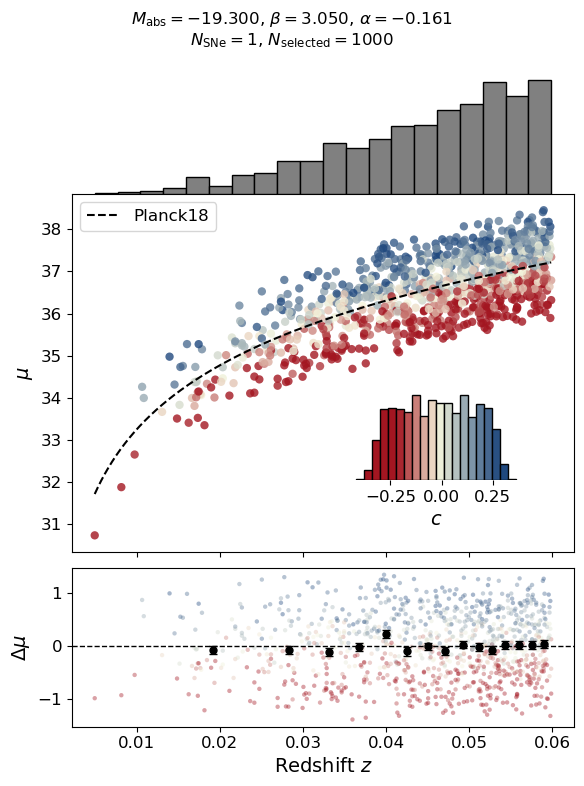

Mean residual: -0.013744346372881988
Residual scatter: 0.608154929293101


(<Figure size 600x800 with 3 Axes>,
 (<Axes: ylabel='$\\mu$'>,
  <Axes: xlabel='Redshift $z$', ylabel='$\\Delta\\mu$'>))

In [6]:
plt_tools.plot_HD(
    example = data_dict,
    params=params,
    default_params=params,
    N_total=1,
    survey_name=survey_name,
)